# Book Catalogue Price Analysis: Books to Scrape

**Pipeline:** 0 Setup > 1 Scraping > 2 Cleaning > 3 EDA > 4 Feature engineering > 5 Linear regression > 6 Interpretation > 7 Recommendations

> This notebook is fully self-contained: the scraper and cleaning functions are defined in cells below (no external `.py` files). Run it from any folder; it creates `data/` and `figures/` next to the notebook.
>
> Install once: `pip install requests beautifulsoup4 lxml pandas numpy matplotlib seaborn scikit-learn statsmodels scipy jupyter`

> Note: books.toscrape.com is a sandbox site with synthetic data. Findings describe this dataset, not the real book market.

## Install dependencies (run once)
Installs the libraries into the same Python environment this notebook is using. If any package is newly installed, restart the kernel afterwards (Kernel > Restart) and then run the notebook from the next cell.

In [1]:
%pip install -q requests beautifulsoup4 lxml pandas numpy matplotlib seaborn scikit-learn statsmodels scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 0. Setup

In [2]:
import re, time, warnings
from pathlib import Path
from urllib.parse import urljoin
import requests
from bs4 import BeautifulSoup
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import statsmodels.api as sm
from scipy import stats
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")

ROOT = Path(".")
RAW_PATH = ROOT / "data" / "raw" / "books_raw.csv"
CLEAN_PATH = ROOT / "data" / "processed" / "books_clean.csv"
FIG_DIR = ROOT / "figures"; FIG_DIR.mkdir(exist_ok=True)
CLEAN_PATH.parent.mkdir(parents=True, exist_ok=True); RAW_PATH.parent.mkdir(parents=True, exist_ok=True)

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## 1. Data acquisition (BeautifulSoup)
The scraper is defined in the next cell. It uses a `requests.Session`, a descriptive User-Agent, a 0.4 s delay between requests, retries with backoff, and CSV checkpoints.
Stage 1 collects title, price, rating and URL from the 50 listing pages. Stage 2 visits each product page for category, availability, description, UPC and tax fields.

Set `FORCE_SCRAPE = True` to re-scrape. Use `MAX_PAGES = 5` first as a smoke test (about 100 books).

**Result:** 1,000 books scraped (14 raw columns), all with unique product URLs.

### 1a. Scraper functions (BeautifulSoup)

In [3]:
from __future__ import annotations

BASE_URL = "https://books.toscrape.com/"
LISTING_URL = BASE_URL + "catalogue/page-{}.html"
HEADERS = {"User-Agent": "Mozilla/5.0 (compatible; BookAnalyticsStudentProject/1.0; educational use)"}
DELAY = 0.4  # seconds between requests


def make_session() -> requests.Session:
    s = requests.Session()
    s.headers.update(HEADERS)
    return s


def get_soup(session: requests.Session, url: str, retries: int = 3, delay: float = DELAY):
    """GET a URL with retries/backoff. Returns BeautifulSoup, or None on 404."""
    for attempt in range(1, retries + 1):
        try:
            resp = session.get(url, timeout=15)
            if resp.status_code == 404:
                return None
            resp.raise_for_status()
            resp.encoding = "utf-8"  # site omits charset; avoids the 'Â£' artefact
            time.sleep(delay)
            return BeautifulSoup(resp.text, "lxml")
        except requests.RequestException as exc:
            wait = 2 ** attempt
            print(f"  [retry {attempt}/{retries}] {url}: {exc} (waiting {wait}s)")
            time.sleep(wait)
    raise RuntimeError(f"Failed to fetch {url} after {retries} attempts")


def parse_listing_page(soup: BeautifulSoup, page_url: str) -> list[dict]:
    """Extract title, price, rating word, availability and product URL from a listing page."""
    rows = []
    for pod in soup.select("article.product_pod"):
        link = pod.h3.a
        rating_classes = pod.select_one("p.star-rating")["class"]  # ['star-rating', 'Three']
        rows.append({
            "title": link["title"],
            "price_raw": pod.select_one("p.price_color").get_text(strip=True),
            "rating_word": next((c for c in rating_classes if c != "star-rating"), None),
            "availability_listing": pod.select_one("p.availability").get_text(strip=True),
            "product_url": urljoin(page_url, link["href"]),
        })
    return rows


def scrape_listings(session: requests.Session, max_pages: int | None = None) -> list[dict]:
    """Walk catalogue/page-N.html until a 404 / empty page (50 pages on the live site)."""
    books, page = [], 1
    while max_pages is None or page <= max_pages:
        url = LISTING_URL.format(page)
        soup = get_soup(session, url)
        if soup is None:
            break
        rows = parse_listing_page(soup, url)
        if not rows:
            break
        books.extend(rows)
        print(f"Listing page {page}: {len(rows)} books (total {len(books)})")
        page += 1
    return books


def parse_product_page(soup: BeautifulSoup) -> dict:
    """Extract category, availability, description and the product-information table."""
    crumbs = [li.get_text(strip=True) for li in soup.select("ul.breadcrumb li")]
    category = crumbs[2] if len(crumbs) >= 3 else None  # Home > Books > <Category> > Title

    avail = soup.select_one("p.availability")
    availability = re.sub(r"\s+", " ", avail.get_text()).strip() if avail else None

    desc_header = soup.select_one("#product_description")
    description = None
    if desc_header is not None:
        p = desc_header.find_next_sibling("p")
        description = p.get_text(strip=True) if p else None

    info = {}
    for tr in soup.select("table.table-striped tr"):
        info[tr.th.get_text(strip=True)] = tr.td.get_text(strip=True)

    return {
        "category": category,
        "availability": availability,
        "description": description,
        "upc": info.get("UPC"),
        "product_type": info.get("Product Type"),
        "price_excl_tax_raw": info.get("Price (excl. tax)"),
        "price_incl_tax_raw": info.get("Price (incl. tax)"),
        "tax_raw": info.get("Tax"),
        "num_reviews": info.get("Number of reviews"),
    }


def scrape_products(session: requests.Session, books: list[dict],
                    checkpoint_every: int = 100, out_path: Path = RAW_PATH) -> pd.DataFrame:
    """Visit every product page, merge detail fields, checkpoint to CSV along the way."""
    out_path.parent.mkdir(parents=True, exist_ok=True)
    full = []
    for i, book in enumerate(books, 1):
        try:
            soup = get_soup(session, book["product_url"])
            details = parse_product_page(soup) if soup else {}
        except RuntimeError as exc:
            print(f"  Skipping {book['product_url']}: {exc}")
            details = {}
        full.append({**book, **details})
        if i % checkpoint_every == 0:
            pd.DataFrame(full).to_csv(out_path, index=False)
            print(f"Product pages: {i}/{len(books)} (checkpoint saved)")
    df = pd.DataFrame(full)
    df.to_csv(out_path, index=False)
    return df


def scrape_catalogue(max_pages: int | None = None) -> pd.DataFrame:
    """Full pipeline. Use max_pages=5 for a quick test (~100 books)."""
    session = make_session()
    books = scrape_listings(session, max_pages=max_pages)
    return scrape_products(session, books)

In [4]:
FORCE_SCRAPE = False
MAX_PAGES = None   # None = whole catalogue (1,000 books, roughly 10 minutes)

if FORCE_SCRAPE or not RAW_PATH.exists():
    raw = scrape_catalogue(max_pages=MAX_PAGES)
else:
    raw = pd.read_csv(RAW_PATH)
print(raw.shape)
raw.head()

(1000, 14)


,title,price_raw,rating_word,availability_listing,product_url,category,availability,description,upc,product_type,price_excl_tax_raw,price_incl_tax_raw,tax_raw,num_reviews
0,A Light in the Attic,£51.77,Three,In stock,https://books.toscrape.com/catalogue/a-light-i...,Poetry,In stock (22 available),It's hard to imagine a world without A Light i...,a897fe39b1053632,Books,£51.77,£51.77,£0.00,0
1,Tipping the Velvet,£53.74,One,In stock,https://books.toscrape.com/catalogue/tipping-t...,Historical Fiction,In stock (20 available),"""Erotic and absorbing...Written with starling ...",90fa61229261140a,Books,£53.74,£53.74,£0.00,0
2,Soumission,£50.10,One,In stock,https://books.toscrape.com/catalogue/soumissio...,Fiction,In stock (20 available),"Dans une France assez proche de la nôtre, un h...",6957f44c3847a760,Books,£50.10,£50.10,£0.00,0
3,Sharp Objects,£47.82,Four,In stock,https://books.toscrape.com/catalogue/sharp-obj...,Mystery,In stock (20 available),"WICKED above her hipbone, GIRL across her hear...",e00eb4fd7b871a48,Books,£47.82,£47.82,£0.00,0
4,Sapiens: A Brief History of Humankind,£54.23,Five,In stock,https://books.toscrape.com/catalogue/sapiens-a...,History,In stock (20 available),From a renowned historian comes a groundbreaki...,4165285e1663650f,Books,£54.23,£54.23,£0.00,0


In [5]:
# Raw sanity checks
print("Rows:", len(raw), "| Unique product URLs:", raw["product_url"].nunique())
assert len(raw) >= 200, "Need at least 200 books"
raw.isna().sum()

Rows: 1000 | Unique product URLs: 1000


title                   0
price_raw               0
rating_word             0
availability_listing    0
product_url             0
category                0
availability            0
description             2
upc                     0
product_type            0
price_excl_tax_raw      0
price_incl_tax_raw      0
tax_raw                 0
num_reviews             0
dtype: int64

## 2. Data cleaning
Steps (functions defined in the next cell):
- Strip the `Â£` encoding artefact and cast prices to float
- Map rating words (One to Five) to integers 1 to 5
- Parse stock text into `in_stock` and `stock_qty`
- Fill missing descriptions with an empty string and add a `has_description` flag
- Remove duplicates (UPC, title + price)
- Text prep: lowercase, strip punctuation, derive `desc_length` and `desc_word_count`
- Drop zero-information columns (`num_reviews` is always 0, `product_type` is always "Books")

**Tags:** this site has no tags field. Category and description text act as the tag-like features.

**Cleaning results:** 1,000 rows in and 1,000 rows out (no UPC duplicates; one title appears twice with different UPCs, so both were kept). Only 2 books lack a description. All tax fields are identical to price (tax is always £0.00), so they are leakage and excluded from modelling. Every review count is 0. All 1,000 books are "In stock", so `in_stock` is constant and carries no information; `stock_qty` ranges from 1 to 22 units (mean 8.6).

### 2a. Cleaning functions

In [6]:
from __future__ import annotations

RATING_MAP = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}


def parse_price(s) -> float:
    """'Â£51.77' or '£51.77' -> 51.77"""
    if pd.isna(s):
        return np.nan
    m = re.search(r"(\d+(?:\.\d+)?)", str(s))
    return float(m.group(1)) if m else np.nan


def parse_stock(text) -> tuple[bool, float]:
    """'In stock (22 available)' -> (True, 22); 'Out of stock' -> (False, 0)."""
    if pd.isna(text):
        return False, np.nan
    t = str(text).lower()
    m = re.search(r"\((\d+)\s+available\)", t)
    qty = float(m.group(1)) if m else (np.nan if "in stock" in t else 0.0)
    return ("in stock" in t), qty


def clean_text(s) -> str:
    """Lowercase, drop punctuation/digits, collapse whitespace."""
    if pd.isna(s):
        return ""
    s = re.sub(r"[^a-z\s]", " ", str(s).lower())
    return re.sub(r"\s+", " ", s).strip()


def clean_books(raw: pd.DataFrame) -> pd.DataFrame:
    df = raw.copy()

    # prices (keep tax columns only for QA, they are NOT model features)
    for col in ["price", "price_excl_tax", "price_incl_tax", "tax"]:
        src = "price_raw" if col == "price" else f"{col}_raw"
        df[col] = df[src].map(parse_price)

    # rating
    df["rating"] = df["rating_word"].str.strip().str.title().map(RATING_MAP)

    # stock
    parsed = df["availability"].map(parse_stock)
    df["in_stock"] = parsed.map(lambda t: t[0]).astype(int)
    df["stock_qty"] = parsed.map(lambda t: t[1])

    # category / title tidy-up
    df["category"] = df["category"].str.strip().str.title()
    df["title"] = df["title"].str.strip()

    # description text features
    df["has_description"] = df["description"].notna().astype(int)
    df["description"] = df["description"].fillna("")
    df["desc_clean"] = df["description"].map(clean_text)
    df["desc_length"] = df["description"].str.len()
    df["desc_word_count"] = df["desc_clean"].str.split().str.len()
    df["title_length"] = df["title"].str.len()

    # duplicates
    if "upc" in df:
        df = df.drop_duplicates(subset="upc")
    df = df.drop_duplicates(subset=["title", "price"])

    # drop zero-information columns and raw strings
    df = df.drop(columns=["num_reviews", "product_type", "availability_listing"], errors="ignore")
    df = df.drop(columns=[c for c in df.columns if c.endswith("_raw")])
    return df.reset_index(drop=True)


def quality_report(df: pd.DataFrame) -> pd.DataFrame:
    """Simple data-quality table: dtype, missing count, unique count."""
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing": df.isna().sum(),
        "unique": df.nunique(),
    })

In [7]:
df = clean_books(raw)
print(df.shape)
quality_report(df)

(1000, 19)


,dtype,missing,unique
title,str,0,999
rating_word,str,0,5
product_url,str,0,1000
category,str,0,50
availability,str,0,21
description,str,0,999
upc,str,0,1000
price,float64,0,903
price_excl_tax,float64,0,903
price_incl_tax,float64,0,903


In [8]:
# Data-quality checks
assert df["price"].between(0, 100).all(), "Unexpected price range"
assert df["rating"].isin([1, 2, 3, 4, 5]).all(), "Unmapped rating"
assert df["upc"].is_unique
# price_incl_tax == price_excl_tax == price on this site (tax is 0): confirms these are leakage
print("Tax columns identical to price:", (df["price_incl_tax"] == df["price"]).mean())
print("Missing descriptions:", (df["has_description"] == 0).sum())
print("Raw reviews all zero (before drop):", (pd.to_numeric(raw["num_reviews"], errors="coerce") == 0).all())
df.to_csv(CLEAN_PATH, index=False)
df.describe().T

Tax columns identical to price: 1.0
Missing descriptions: 2
Raw reviews all zero (before drop): True


,count,mean,std,min,25%,50%,75%,max
price,1000.0,35.07035,14.446690,10.0,22.1075,35.98,47.4575,59.99
price_excl_tax,1000.0,35.07035,14.446690,10.0,22.1075,35.98,47.4575,59.99
price_incl_tax,1000.0,35.07035,14.446690,10.0,22.1075,35.98,47.4575,59.99
tax,1000.0,0.00000,0.000000,0.0,0.0000,0.00,0.0000,0.00
rating,1000.0,2.92300,1.434967,1.0,2.0000,3.00,4.0000,5.00
in_stock,1000.0,1.00000,0.000000,1.0,1.0000,1.00,1.0000,1.00
stock_qty,1000.0,8.58500,5.654622,1.0,3.0000,7.00,14.0000,22.00
has_description,1000.0,0.99800,0.044699,0.0,1.0000,1.00,1.0000,1.00
desc_length,1000.0,1431.62800,669.324296,0.0,1069.7500,1348.50,1681.5000,8646.00
desc_word_count,1000.0,245.25100,110.671090,0.0,185.0000,231.00,291.0000,1408.00


## 3. Exploratory data analysis

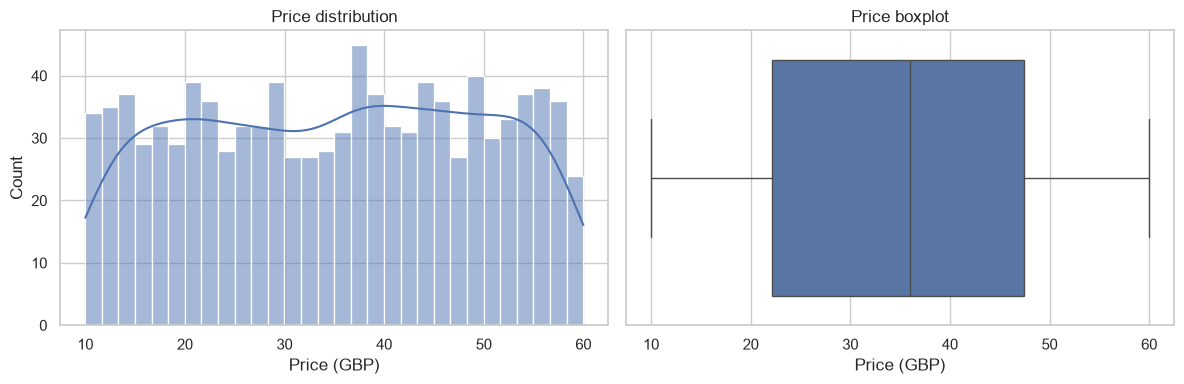

count    1000.00
mean       35.07
std        14.45
min        10.00
25%        22.11
50%        35.98
75%        47.46
max        59.99
Name: price, dtype: float64


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["price"], kde=True, bins=30, ax=ax[0]); ax[0].set(title="Price distribution", xlabel="Price (GBP)")
sns.boxplot(x=df["price"], ax=ax[1]); ax[1].set(title="Price boxplot", xlabel="Price (GBP)")
savefig("01_price_distribution"); plt.show()
print(df["price"].describe().round(2))

**Takeaway:** Prices run from £10.00 to £59.99 (mean £35.07, median £35.98, SD £14.45), and the middle 50% of books sit between £22.11 and £47.46. The histogram is roughly flat across the whole range, with no pronounced peak and no outliers, and the mean and median are close. This is what an evenly spread (randomly assigned) price list looks like, rather than clustering around typical price points.

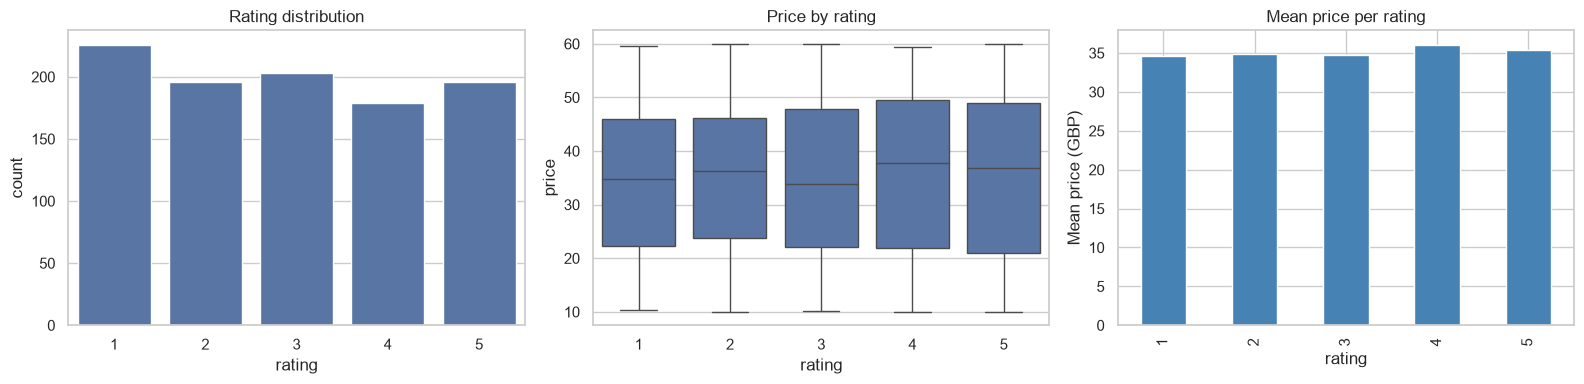

ANOVA price ~ rating: F_onewayResult(statistic=np.float64(0.36594095586137154), pvalue=np.float64(0.8329710147157289))
Spearman rating vs price: SignificanceResult(statistic=np.float64(0.02921568643020118), pvalue=np.float64(0.35604753366752295))


In [10]:
order = [1, 2, 3, 4, 5]
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(x="rating", data=df, order=order, ax=ax[0]); ax[0].set(title="Rating distribution")
sns.boxplot(x="rating", y="price", data=df, order=order, ax=ax[1]); ax[1].set(title="Price by rating")
df.groupby("rating")["price"].mean().reindex(order).plot(kind="bar", ax=ax[2], color="steelblue")
ax[2].set(title="Mean price per rating", ylabel="Mean price (GBP)")
savefig("02_rating_price"); plt.show()

groups = [g["price"].values for _, g in df.groupby("rating")]
print("ANOVA price ~ rating:", stats.f_oneway(*groups))
print("Spearman rating vs price:", stats.spearmanr(df["rating"], df["price"]))

**Takeaway:** Ratings are spread fairly evenly: each star level holds roughly 180 to 225 books, with 1-star the most common. Mean price is about £35 to £36 at every rating level and the boxplots overlap almost completely. ANOVA gives F = 0.37 (p = 0.833) and the Spearman correlation is 0.029 (p = 0.356), so there is no statistically significant relationship between rating and price. Higher-rated books are not priced higher.

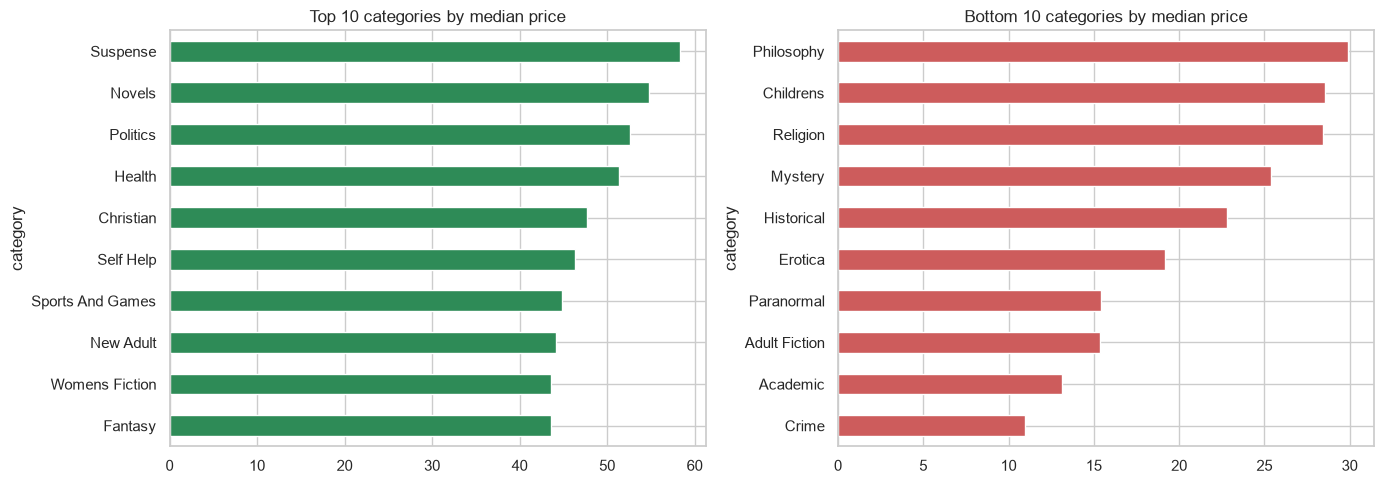

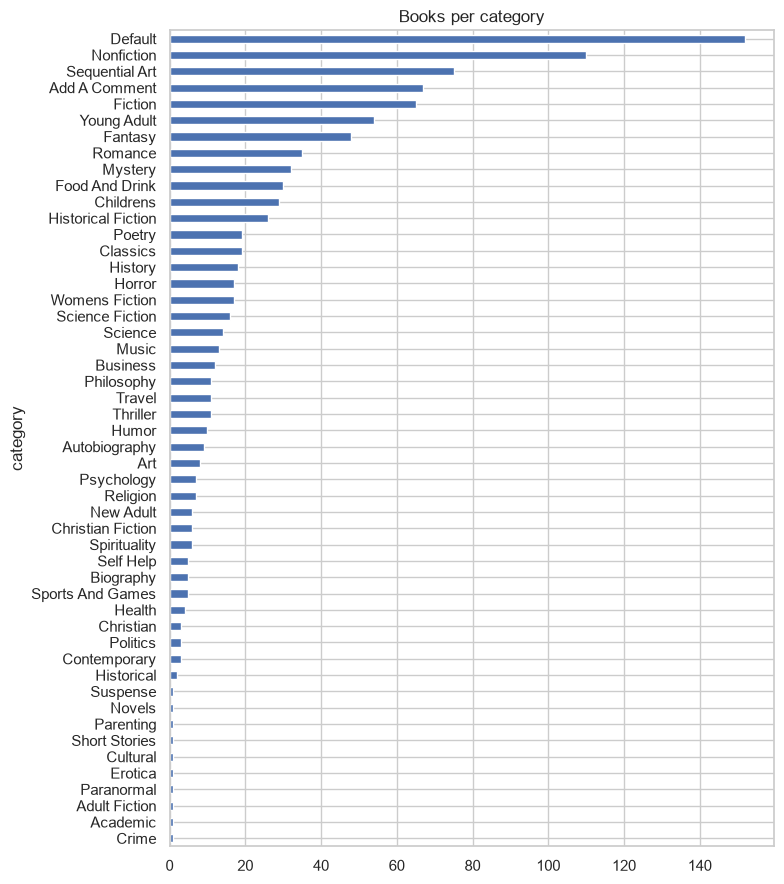

KruskalResult(statistic=np.float64(21.558349686521197), pvalue=np.float64(0.9517740265887351))


In [11]:
cat = df.groupby("category")["price"].agg(["count", "median", "mean"]).sort_values("median")
top, bottom = cat.tail(10), cat.head(10)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
top["median"].plot(kind="barh", ax=ax[0], color="seagreen"); ax[0].set(title="Top 10 categories by median price")
bottom["median"].plot(kind="barh", ax=ax[1], color="indianred"); ax[1].set(title="Bottom 10 categories by median price")
savefig("03_category_median_price"); plt.show()

fig, ax = plt.subplots(figsize=(8, 9))
cat["count"].sort_values().plot(kind="barh", ax=ax); ax.set(title="Books per category")
savefig("04_category_sizes"); plt.show()
print(stats.kruskal(*[g["price"].values for _, g in df.groupby("category") if len(g) >= 5]))

**Takeaway:** Median prices range from about £11 (Crime) to about £58 (Suspense), which looks like a large genre effect, but it is misleading. The extreme categories are tiny: Suspense, Novels, Crime, Academic, Adult Fiction and Paranormal each contain a single book, and about ten categories in total have just one book, so their "medians" are single prices. The largest categories (Default, Nonfiction, Sequential Art, Add a Comment, Fiction) all sit near the overall median. A Kruskal-Wallis test across categories with at least 5 books gives H = 21.56 (p = 0.952), so category differences in price are not statistically significant.

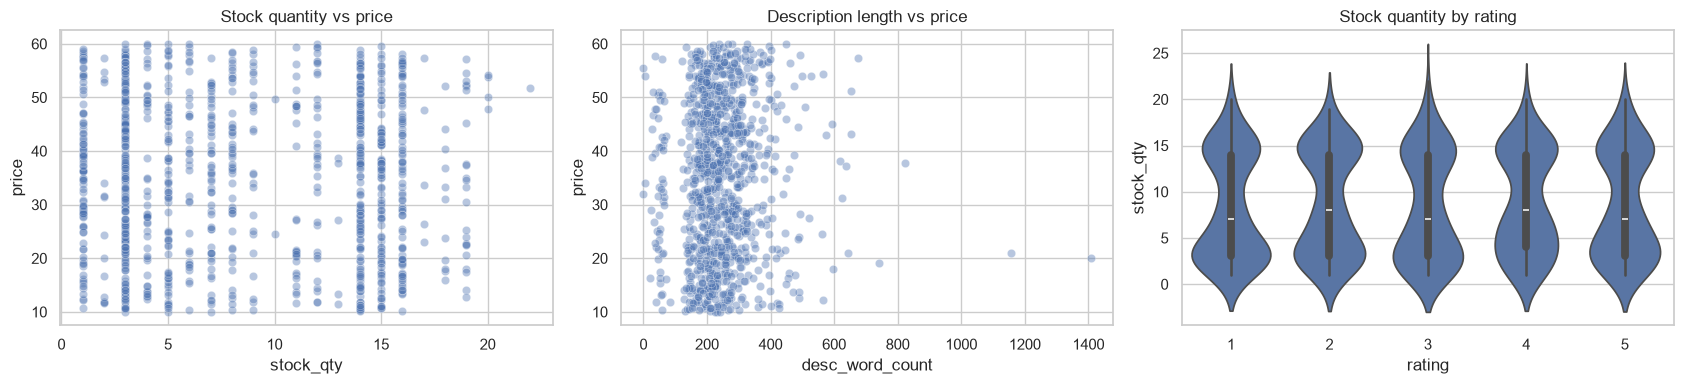

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
sns.scatterplot(x="stock_qty", y="price", data=df, alpha=.4, ax=ax[0]); ax[0].set(title="Stock quantity vs price")
sns.scatterplot(x="desc_word_count", y="price", data=df, alpha=.4, ax=ax[1]); ax[1].set(title="Description length vs price")
sns.violinplot(x="rating", y="stock_qty", data=df, order=order, ax=ax[2]); ax[2].set(title="Stock quantity by rating")
savefig("05_stock_desc_scatter"); plt.show()

**Takeaway:** Neither stock quantity nor description length shows any visible pattern against price; both scatterplots are shapeless clouds. The correlation matrix below confirms it: stock quantity vs price r = -0.01 and description word count vs price r = 0.03. Stock levels (1 to 22 units) and description length do not signal price.

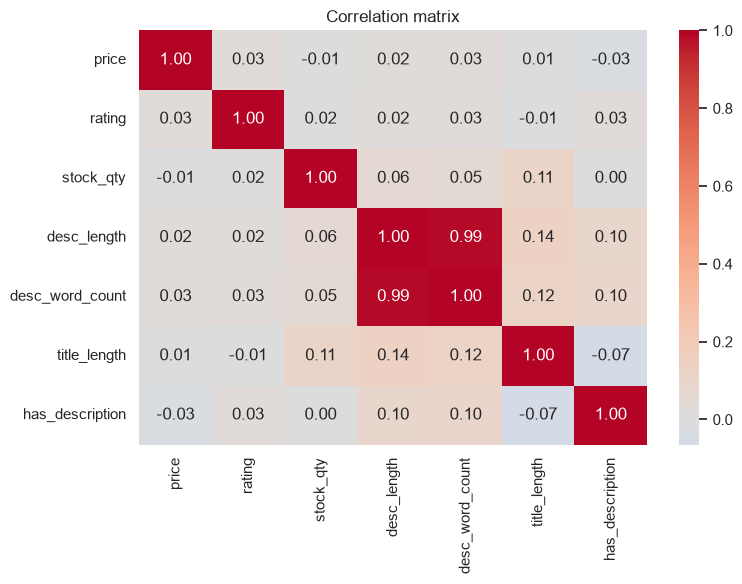

In [13]:
num_cols = ["price", "rating", "stock_qty", "desc_length", "desc_word_count", "title_length", "has_description"]
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix"); savefig("06_correlation_heatmap"); plt.show()

**Takeaway:** Every correlation with price is tiny (|r| ≤ 0.03): rating 0.03, description word count 0.03, description length 0.02, title length 0.01, stock quantity -0.01, has_description -0.03. The only strong relationship is between `desc_length` and `desc_word_count` (r = 0.99), so they carry almost identical information, which causes the multicollinearity seen later (VIF about 62).

In [14]:
# Optional: most frequent description terms (simple TF-IDF) split by price tier
from sklearn.feature_extraction.text import TfidfVectorizer
df["price_tier"] = pd.qcut(df["price"], 3, labels=["low", "mid", "high"])
tfidf = TfidfVectorizer(stop_words="english", max_features=500, min_df=5)
X_txt = tfidf.fit_transform(df["desc_clean"])
terms = np.array(tfidf.get_feature_names_out())
for tier in ["low", "mid", "high"]:
    mean_w = np.asarray(X_txt[(df["price_tier"] == tier).values].mean(axis=0)).ravel()
    print(f"{tier:>4}: {', '.join(terms[mean_w.argsort()[::-1][:10]])}")

 low: new, life, world, time, love, book, story, home, year, family
 mid: new, life, book, love, world, years, family, time, story, year
high: life, new, world, love, story, family, book, old, years, like


**Takeaway (description terms by price tier):** The top terms are almost the same in the low, mid and high price thirds (new, life, world, love, story, family, book). Seven of the top 10 terms are shared between the low and high tiers (Jaccard overlap about 54%), so description wording does not separate cheap from expensive books.

## 4. Feature engineering
- Ordinal `rating`, numeric `stock_qty`, `desc_length`, `desc_word_count`, `title_length`, `has_description`
- One-hot `category` for all categories (first level dropped as the reference)
- `desc_length` and `desc_word_count` are nearly collinear; check the VIF output in section 5
- **Leakage:** `price_excl_tax`, `price_incl_tax`, `tax` are excluded (they duplicate the target)

In [15]:
print("Categories:", df["category"].nunique())

num_feats = ["rating", "stock_qty", "desc_length", "desc_word_count", "title_length", "has_description"]
X = pd.concat([df[num_feats], pd.get_dummies(df["category"], prefix="cat", drop_first=True)], axis=1).astype(float)
X["stock_qty"] = X["stock_qty"].fillna(X["stock_qty"].median())
y = df["price"]
print(X.shape)

Categories: 50
(1000, 55)


## 5. Predictive modelling: linear regression

In [16]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

lr = LinearRegression().fit(X_train, y_train)

def metrics(model, Xs, ys, label):
    p = model.predict(Xs); n, k = Xs.shape
    r2 = r2_score(ys, p)
    return {"set": label, "R2": r2, "Adj_R2": 1 - (1 - r2) * (n - 1) / (n - k - 1),
            "MAE": mean_absolute_error(ys, p), "RMSE": np.sqrt(mean_squared_error(ys, p))}

res = pd.DataFrame([metrics(lr, X_train, y_train, "train"), metrics(lr, X_test, y_test, "test")]).round(3)
display(res)

cv = cross_val_score(LinearRegression(), X, y, cv=5, scoring="r2")
print("5-fold CV R2:", cv.round(3), "mean:", cv.mean().round(3))

,set,R2,Adj_R2,MAE,RMSE
0,train,0.067,-0.002,11.852,13.928
1,test,-0.142,-0.578,13.237,15.489


5-fold CV R2: [-0.048 -0.033 -0.158 -0.064 -0.117] mean: -0.084


In [17]:
# statsmodels OLS for coefficients, p-values and diagnostics
ols = sm.OLS(y_train, sm.add_constant(X_train)).fit()
print(ols.summary().tables[0])
coef = pd.DataFrame({"coef": ols.params, "p_value": ols.pvalues, "ci_low": ols.conf_int()[0], "ci_high": ols.conf_int()[1]}).round(3)
coef.sort_values("p_value").head(15)

                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.067
Model:                            OLS   Adj. R-squared:                 -0.001
Method:                 Least Squares   F-statistic:                    0.9894
Date:                Thu, 22 Oct 2026   Prob (F-statistic):              0.498
Time:                        17:55:03   Log-Likelihood:                -3242.3
No. Observations:                 800   AIC:                             6595.
Df Residuals:                     745   BIC:                             6852.
Df Model:                          54                                         
Covariance Type:            nonrobust                                         


,coef,p_value,ci_low,ci_high
cat_Politics,43.972,0.009,10.878,77.066
cat_Health,42.018,0.014,8.660,75.377
cat_Suspense,48.098,0.019,7.905,88.290
cat_Art,34.336,0.029,3.598,65.074
cat_Sports And Games,35.489,0.030,3.542,67.437
cat_Humor,33.961,0.032,2.973,64.949
desc_word_count,0.086,0.037,0.005,0.166
cat_Travel,32.096,0.039,1.576,62.617
cat_Fantasy,30.172,0.041,1.208,59.136
cat_New Adult,32.719,0.044,0.910,64.528


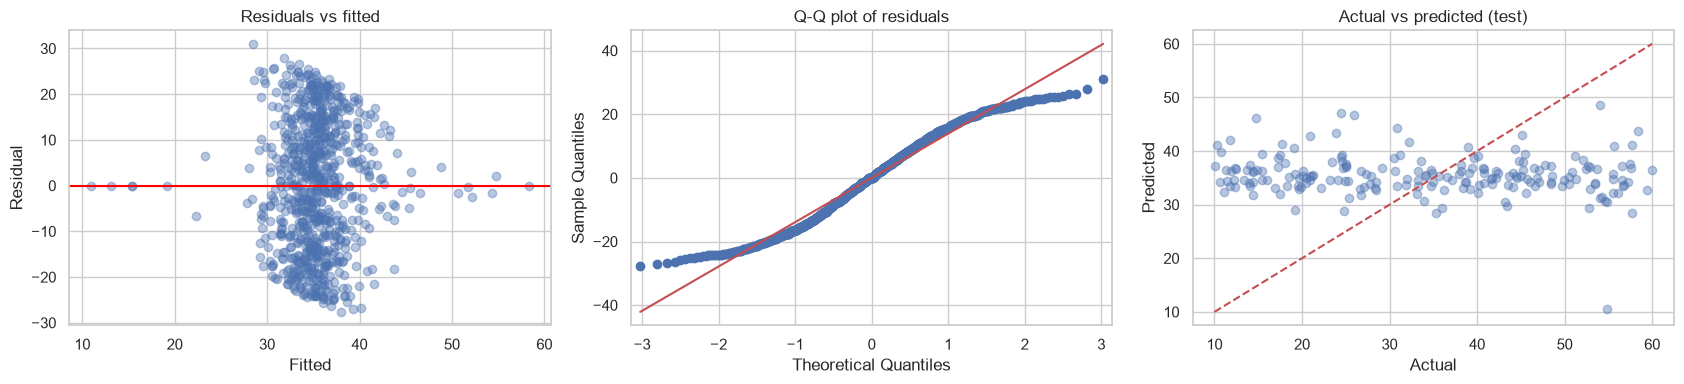

rating              1.01
stock_qty           1.02
desc_length        62.74
desc_word_count    62.34
title_length        1.07
has_description     1.02
dtype: float64


In [18]:
fitted, resid = ols.fittedvalues, ols.resid
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].scatter(fitted, resid, alpha=.4); ax[0].axhline(0, color="red"); ax[0].set(title="Residuals vs fitted", xlabel="Fitted", ylabel="Residual")
sm.qqplot(resid, line="s", ax=ax[1]); ax[1].set_title("Q-Q plot of residuals")
ax[2].scatter(y_test, lr.predict(X_test), alpha=.4); lim = [y.min(), y.max()]; ax[2].plot(lim, lim, "r--")
ax[2].set(title="Actual vs predicted (test)", xlabel="Actual", ylabel="Predicted")
savefig("07_diagnostics"); plt.show()

# Multicollinearity (VIF) on numeric features
Xc = sm.add_constant(X_train[num_feats])
print(pd.Series([variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])], index=num_feats).round(2))

In [19]:
# Optional: Ridge for comparison
ridge = RidgeCV(alphas=np.logspace(-2, 3, 30)).fit(X_train, y_train)
print("Ridge alpha:", round(ridge.alpha_, 3))
pd.DataFrame([metrics(ridge, X_test, y_test, "ridge test"), metrics(lr, X_test, y_test, "OLS test")]).round(3)

Ridge alpha: 1000.0


,set,R2,Adj_R2,MAE,RMSE
0,ridge test,-0.022,-0.412,12.810,14.652
1,OLS test,-0.142,-0.578,13.237,15.489


## 6. Interpretation and limitations

**Predictive power is negligible.** On unseen books the model does worse than simply predicting the average price: test R² = -0.142 (adjusted R² = -0.578), and 5-fold cross-validated R² averages -0.084 (folds from -0.158 to -0.033). Test MAE is £13.24 and RMSE £15.49, which is about 107% of the standard deviation of price (£14.45). The "actual vs predicted" plot shows predictions in a flat band around £35 whatever the true price.

**Overfitting.** Train R² is 0.067 but test R² is -0.142 (a gap of 0.21) with 55 predictors on 800 training books. Adjusted R² is about zero even on the training data, so the fit is noise. OLS reports 54 effective predictors for 55 columns, which suggests one dummy was all zeros in the training split (most likely a single-book category that landed in the test set).

**Overall significance.** The OLS F-test (p = 0.498) shows the features are not jointly significant.

**Individual coefficients.** Ten of the 54 coefficients have p < 0.05: cat_Politics (+£43.97, p = 0.009), cat_Health (+£42.02, p = 0.014), cat_Suspense (+£48.10, p = 0.019), cat_Art (+£34.34, p = 0.029), cat_Sports And Games (+£35.49, p = 0.030), cat_Humor (+£33.96, p = 0.032), desc_word_count (+£0.086 per word, p = 0.037), cat_Travel (+£32.10, p = 0.039), cat_Fantasy (+£30.17, p = 0.041) and cat_New Adult (+£32.72, p = 0.044). About 2.7 would be expected by chance alone with this many tests, and the joint F-test is not significant, so these should not be treated as real effects. The category coefficients are all large and positive because they are measured against the reference category (Academic, the alphabetically first), which holds about one book priced near £13; they reflect that one cheap book, not genre premiums. desc_word_count (+0.086) and desc_length (-0.013, p = 0.051) are collinear (VIF about 62 each) and largely offset each other, so neither can be read on its own.

**Diagnostics.** Fitted values cluster tightly around £30 to £40 while residuals spread about ±25, so the model leaves almost all variation unexplained. The Q-Q plot is S-shaped (light tails), as expected for a bounded, near-uniform target, so residuals are not normal and p-values are only approximate.

**Ridge comparison.** RidgeCV chose alpha = 1000, the top of the search grid, meaning it shrinks the coefficients almost to zero. Test R² improves to -0.022 (MAE £12.81, RMSE £14.65) but is still not better than predicting the average, which confirms there is no usable signal.

**Limitations**
- Sandbox data: the site states that prices and ratings were randomly assigned, so results describe this dataset, not the real book market.
- No sales, popularity, author, publisher, format or publication-year variables are available.
- Every review count is 0 and every book is in stock, so those fields add no information.
- Many categories have only 1 to 4 books, so category estimates are unstable.
- Linear model only, with collinear description-length features.

## 7. Conclusions and recommendations

**Conclusion:** On Books to Scrape, none of the available attributes (star rating, category, stock quantity, description length or wording) predict price. All correlations are within ±0.03, the rating and category tests are not significant, and the regression performs worse than predicting the mean on unseen data (test R² = -0.142). Prices look randomly assigned across £10 to £60, which the site itself says.

**Retailers**
- Do not use star rating, genre, stock level or description length as pricing signals for this catalogue; together they explain none of the price variation on unseen books.
- Set prices using information not in this dataset, such as cost, sales velocity, competitor prices and edition or format.
- Avoid category-based price rules: the apparent genre gaps come from categories with one to four books (Kruskal-Wallis p = 0.952).

**Publishers**
- Catalogue attributes alone cannot justify a price point here; collect sales, format and publication data before building a pricing model.
- Longer or richer descriptions are not associated with higher prices (r = 0.03), so do not expect blurb length to support a price premium.

**Data-driven buyers**
- Price is not a reliable proxy for rating (Spearman rho = 0.029, p = 0.356); a dearer book is no more likely to be highly rated.
- Compare prices within a category, and ignore medians from categories with fewer than about 10 books.

**Next steps:** enrich the data with real sales, author, publisher and publication-year fields; try tree-based models and a hierarchical category model; and repeat the analysis on a real retailer catalogue before drawing market conclusions.